In [76]:
import torch
import torch.nn as nn
import torch.utils.data as D

import numpy as np
import matplotlib.pyplot as plt
import tqdm
from time import time_ns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Currently using {DEVICE}")

Currently using cpu


In [77]:
from src.twoddensity import *
from src.model import EBM2

In [78]:
torch.manual_seed(0)

In [79]:
# The seed (duh)
SEED = 0

# Data
SZ_GAUS = (1, 2)
N_SAMPLES = 500
N_CLASSES = 5

# Training
BATCH_SIZE = 32
TRAIN_PER = 0.8
SHUFFLE = False

# Model
N_HEAD = 4
HID_DIM_SIZE = 32
NETWORK_DEPTH = 2

In [80]:
X, y, means, covs = mog_dataset(
    n_samples=N_SAMPLES, n_classes=N_CLASSES, std_range=(0.03, 0.09), seed=SEED
)
sep = int(N_SAMPLES * TRAIN_PER)
Xtrain, Xtest, ytrain, ytest = X[:sep], X[sep:], y[:sep], y[sep:]
data_train, data_test = D.TensorDataset(Xtrain, ytrain), D.TensorDataset(Xtest, ytest)
train_dataloader = D.DataLoader(data_train, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = D.DataLoader(data_test, batch_size=BATCH_SIZE)

In [ ]:
params = torch.load("./models/gauss/" + "EBM2_1500_epochs_(1, 2)_shape_4_heads_1794056478936942048.pth")

model = EBM2(n_head=N_HEAD, hid_dim=HID_DIM_SIZE, depth=NETWORK_DEPTH)
model.load_state_dict(params)
model.to(DEVICE)

EBM2(
  (heads): ModuleList(
    (0-3): 4 x EnHead2(
      (net): Sequential(
        (0): Linear(in_features=2, out_features=32, bias=True)
        (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (2): Linear(in_features=32, out_features=32, bias=True)
        (3): Linear(in_features=32, out_features=32, bias=True)
        (4): Linear(in_features=32, out_features=1, bias=True)
      )
    )
  )
)

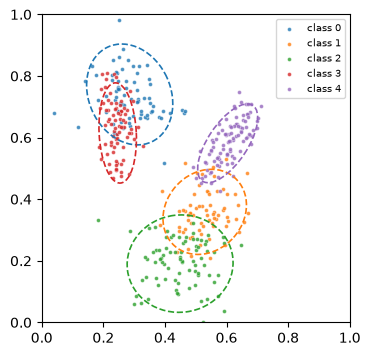

In [82]:
gen = plot_gm_points(Xtrain, ytrain, centers=means, covs=covs)

In [83]:
from src.sampler import ReplaySampler

n_samples = 1000

sampler = ReplaySampler(model=model, img_shape=SZ_GAUS, buffer_size=600, noise_fraction=0.05, device=DEVICE)
model.to(DEVICE)
samples = sampler.generate(n_samples, steps=200, step_size=0.1, noise_std=0.005)
samples = samples.squeeze(1)

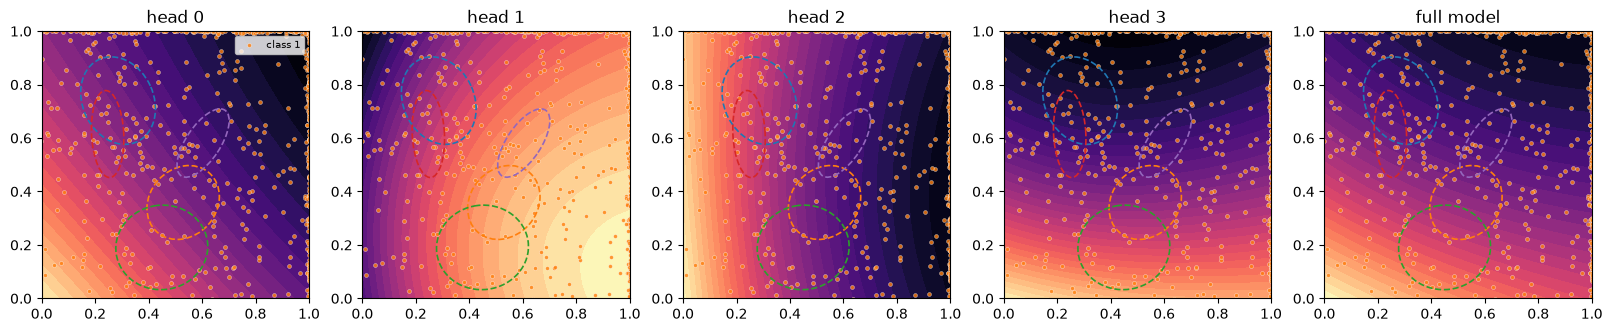

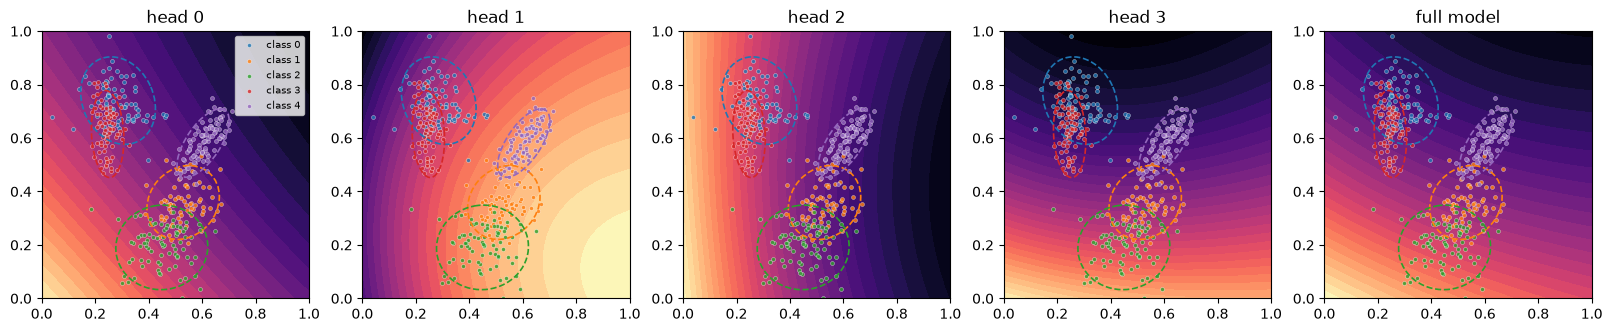

In [84]:
data = plot_gm_points(samples, torch.ones(n_samples, dtype=torch.long), model=model, centers=means, covs=covs)
gen = plot_gm_points(Xtrain, ytrain, model=model, centers=means, covs=covs)

array([<Axes: title={'center': 'head 0'}>,
       <Axes: title={'center': 'head 1'}>,
       <Axes: title={'center': 'head 2'}>,
       <Axes: title={'center': 'head 3'}>,
       <Axes: title={'center': 'full model'}>], dtype=object)

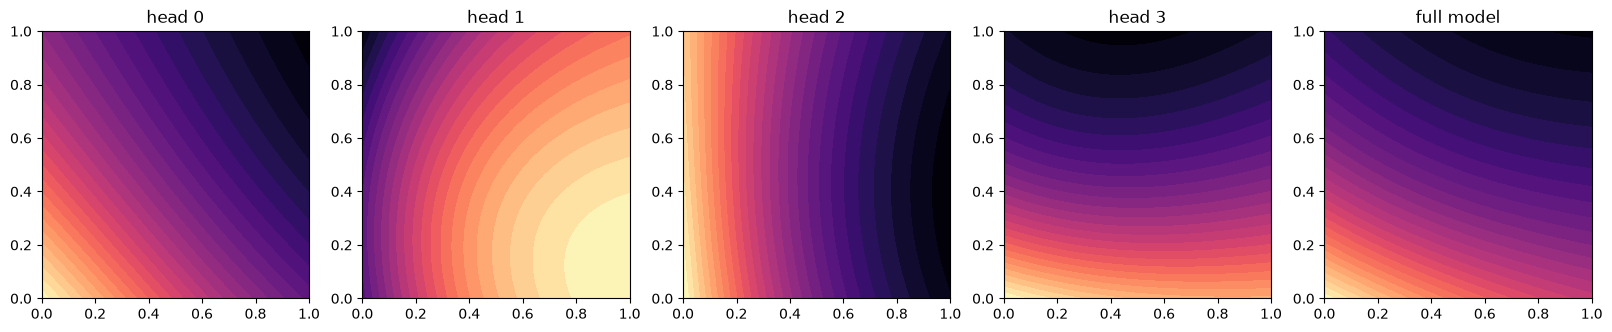

In [85]:
plot_model_density(model)

In [86]:
samples.shape

torch.Size([1000, 2])